In [1]:
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv("data/train.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'data/train.csv'

In [3]:
import os

os.getcwd()

'/Users/sphoorthireddymunnangi/Documents/social-media-comment-moderator/notebooks'

In [4]:
os.getcwd()

'/Users/sphoorthireddymunnangi/Documents/social-media-comment-moderator/notebooks'

In [5]:
df = pd.read_csv("../data/train.csv")

In [6]:
os.getcwd()

'/Users/sphoorthireddymunnangi/Documents/social-media-comment-moderator/notebooks'

In [7]:
df.shape

(159571, 8)

In [8]:
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   id             159571 non-null  str  
 1   comment_text   159571 non-null  str  
 2   toxic          159571 non-null  int64
 3   severe_toxic   159571 non-null  int64
 4   obscene        159571 non-null  int64
 5   threat         159571 non-null  int64
 6   insult         159571 non-null  int64
 7   identity_hate  159571 non-null  int64
dtypes: int64(6), str(2)
memory usage: 9.7 MB


In [10]:
df.isnull().sum()

id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   id             159571 non-null  str  
 1   comment_text   159571 non-null  str  
 2   toxic          159571 non-null  int64
 3   severe_toxic   159571 non-null  int64
 4   obscene        159571 non-null  int64
 5   threat         159571 non-null  int64
 6   insult         159571 non-null  int64
 7   identity_hate  159571 non-null  int64
dtypes: int64(6), str(2)
memory usage: 9.7 MB


In [12]:
label_columns = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

label_counts = df[label_columns].sum().sort_values(ascending=False)

label_counts

toxic            15294
obscene           8449
insult            7877
severe_toxic      1595
identity_hate     1405
threat             478
dtype: int64

In [15]:
label_percentages = (
    df[label_columns].mean() * 100
).sort_values(ascending=False)

label_percentages

toxic            9.584448
obscene          5.294822
insult           4.936361
severe_toxic     0.999555
identity_hate    0.880486
threat           0.299553
dtype: float64

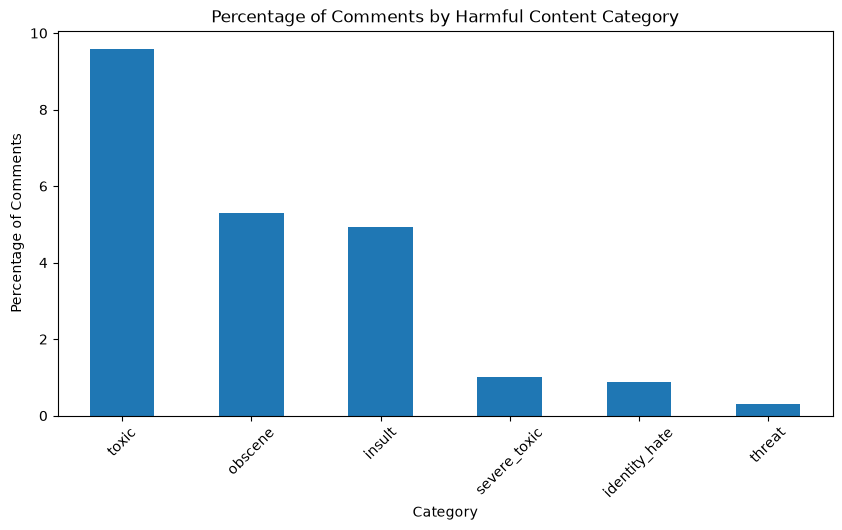

In [16]:
label_percentages.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Percentage of Comments by Harmful Content Category")
plt.xlabel("Category")
plt.ylabel("Percentage of Comments")
plt.xticks(rotation=45)
plt.show()

In [17]:
harmful_comments = (df[label_columns].sum(axis=1) > 0).sum()

harmful_comments

np.int64(16225)

In [18]:
harmful_percentage = harmful_comments / len(df) * 100

harmful_percentage

np.float64(10.167887648758233)

In [19]:
df["is_harmful"] = (df[label_columns].sum(axis=1) > 0).astype(int)

In [20]:
df["is_harmful"].value_counts()

is_harmful
0    143346
1     16225
Name: count, dtype: int64

In [21]:
df["label_count"] = df[label_columns].sum(axis=1)

In [22]:
df["label_count"].value_counts().sort_index()

label_count
0    143346
1      6360
2      3480
3      4209
4      1760
5       385
6        31
Name: count, dtype: int64

In [23]:
multi_label_comments = (df["label_count"] > 1).sum()

multi_label_comments

np.int64(9865)

In [24]:
multi_label_percentage = multi_label_comments / harmful_comments * 100

multi_label_percentage

np.float64(60.801232665639446)

In [25]:
df["id"].duplicated().sum()

np.int64(0)

In [26]:
df["comment_text"].duplicated().sum()

np.int64(0)

In [27]:
(df["comment_text"].str.strip() == "").sum()

np.int64(0)

## Initial Data Quality and Label Distribution Findings

- The dataset contains 159,571 comments and 8 original columns.
- No missing values were found.
- No duplicate comment IDs were found.
- No duplicate comment text was found.
- No blank comments were found.
- 16,225 comments (10.17%) contain at least one harmful-content label.
- 143,346 comments (89.83%) contain no harmful-content labels.
- Toxic content is the most common harmful label (9.58% of all comments).
- Threat is the least common harmful label (0.30% of all comments).
- 9,865 harmful comments (60.80%) contain more than one harmful-content label.
- The dataset is therefore both class-imbalanced and multi-label.

In [28]:
df["word_count"] = df["comment_text"].str.split().str.len()

df["word_count"].describe()

count    159571.000000
mean         67.273527
std          99.230702
min           1.000000
25%          17.000000
50%          36.000000
75%          75.000000
max        1411.000000
Name: word_count, dtype: float64

In [29]:
df.groupby("is_harmful")["word_count"].agg(["count", "mean", "median"])

,count,mean,median
is_harmful,,,
0,143346,68.921065,38.0
1,16225,52.717720,23.0


In [30]:
df[df["is_harmful"] == 1][
    ["comment_text"] + label_columns
].head(10)

,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
6,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1,1,1,0,1,0
12,Hey... what is it..\n@ | talk .\nWhat is it......,1,0,0,0,0,0
16,"Bye! \n\nDon't look, come or think of comming ...",1,0,0,0,0,0
42,You are gay or antisemmitian? \n\nArchangel WH...,1,0,1,0,1,1
43,"FUCK YOUR FILTHY MOTHER IN THE ASS, DRY!",1,0,1,0,1,0
44,I'm Sorry \n\nI'm sorry I screwed around with ...,1,0,0,0,0,0
51,GET FUCKED UP. GET FUCKEEED UP. GOT A DRINK T...,1,0,1,0,0,0
55,Stupid peace of shit stop deleting my stuff as...,1,1,1,0,1,0
56,=Tony Sidaway is obviously a fistfuckee. He lo...,1,0,1,0,1,0
58,My Band Page's deletion. You thought I was gon...,1,0,1,0,0,0
